# Online Non-Negative Matrix Factorization using Hebbian/Anti-Hebbian network

A third-party reimplementation of the paper: "A Hebbian/Anti-Hebbian Network Derived from Online Non-Negative Matrix Factorization Can Cluster and Discover Sparse Features"
https://arxiv.org/abs/1503.00680

In [1]:
import matlab.engine

In [2]:
eng = matlab.engine.start_matlab()

s = eng.genpath("/home/kushal/repos/NMFLibrary/")
eng.addpath(s, nargout=0)

In [1]:
import numpy as np
import fastplotlib as fpl
import matplotlib.pyplot as plt
%matplotlib inline
import random

WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
Unable to find extension: VK_EXT_swapchain_colorspace
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),AMD RADV POLARIS10 (ACO),DiscreteGPU,Vulkan,Mesa 20.3.5 (ACO)
❗ limited,"llvmpipe (LLVM 11.0.1, 256 bits)",CPU,Vulkan,Mesa 20.3.5 (LLVM 11.0.1)
❌,"Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1)",Unknown,OpenGL,4.6 (Core Profile) Mesa 20.3.5


To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


## Dataset
First prepare the dataset for clustering.

In [2]:
def generate_data(
        n_timepoints: int,
        n_components: int,
        noise: int,
        n_pixels: int | tuple[int, int],  # n_pixels PER component, if a tuple a random number of pixles within the range is used
        n_pixels_bg,
        interp_factor: int = 2,
        firing_prop: float = 0.005,
) -> tuple[np.ndarray, np.ndarray]:
    """

    Parameters
    ----------
    n_timepoints: int

    n_components: int

    noise: int

    n_pixels: int, or (min, max) range
        n_pixels PER components, if (min, max) range is given then a random number of pixels within this range
        is used for each component

    n_pixels_bg: int

    interp_factor: int
        interpolation factor

    Returns
    -------
    np.ndarray, np.ndarray
        data [pixels, n_timepoints * interp_factor], truth labels: 1D array 0 is background

    """

    clean = np.zeros((n_components, n_timepoints * interp_factor))

    x = 0
    a = 0.7

    b = 0

    spikes = list()

    for i in range(n_components):
        spikes.append((np.random.rand(n_timepoints) < firing_prop).astype(float))

    for c_ix in range(n_components):
        for i in range(2, n_timepoints):
            clean[c_ix, i] = (a * clean[c_ix, i - 1]) + (b * clean[c_ix, i - 2]) + (50 * spikes[c_ix][i])

        x_ = np.arange(0, n_timepoints * interp_factor)
        xp_ = np.linspace(0, n_timepoints * interp_factor, n_timepoints)
        clean[c_ix] = np.interp(x_, xp_, fp=clean[c_ix, :n_timepoints])

    n_timepoints *= interp_factor

    series = list()
    labels = list()

    for i in range(n_components):
        # determine number of pixels for this component
        if isinstance(n_pixels, int):
            _n_pixels_iter = n_pixels
        elif isinstance(n_pixels, tuple):
            _n_pixels_iter = np.random.randint(low=n_pixels[0], high=n_pixels[1])

        for j in range(_n_pixels_iter):
            series.append(clean[i] + np.random.normal(scale=noise, size=n_timepoints))
            labels.append(i + 1)

    # series = np.vstack(series)

    bg_pixels = [np.random.normal(scale=noise, size=n_timepoints) for i in range(n_pixels_bg)]
    series = np.vstack([*series, *bg_pixels])
    labels = np.array([*labels, *[0 for i in range(len(bg_pixels))]])

    return series, labels

## Training

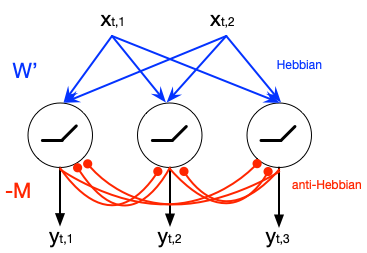

Activation of the output node is,

$$
y_{T,i} = ReLU(W_{T,i} x_T - M_{T,i} y_T)
$$

Weight update rule is

$$
\hat{Y}_{T,i} = \hat{Y}_{T-1,i} + y^2_{T-1,i} 
$$

$$
W_{T,i,j} = W_{T-1,i,j} + \frac{y_{T-1,i} \left( x_{T-1,j} - W_{T-1,i,j} y_{T-1,i} \right)} {\hat{Y}_{T,i}} 
$$

$$
M_{T,i,j\ne i} = M_{T-1,i,j} + \frac{y_{T-1,i} \left( y_{T-1,j} - M_{T-1,i,j} y_{T-1,i}  \right) } { \hat{Y}_{T,i} }
$$

In [3]:
def update_weight(W, M, x_t, y_t, y_hat):
    """ Update weight matrix of W and M.
    Equation (8) in the original paper.
    """
    y_dim = y_t.shape[0]
    y_hat += (y_t * y_t)
    
    # (3,1) x (1,2) = (3,2)
    dW = y_t[:,np.newaxis].dot( x_t[np.newaxis,:] - (W.T.dot(y_t[:,np.newaxis])).T)
    #dW = dW / y_hat[:,np.newaxis]
    # (3, 2)
    
    for i in range(y_dim):
        if y_hat[i] > 0:
            W[i] += (dW[i] / y_hat[i])
    
    # (3,1) x (1,3) = (3,3)
    dM = y_t[:,np.newaxis].dot( y_t[np.newaxis,:] - (M.T.dot(y_t[:,np.newaxis])).T)
    #dM = dM / y_hat[:,np.newaxis]
    
    # Set diagonal elements to zero
    for i in range(M.shape[0]):
        dM[i,i] = 0.0
    
    for i in range(y_dim):
        if y_hat[i] > 0:
            M[i] += (dM[i] / y_hat[i])

If the i-th degree of freedom has not been utilized, then adjust the output.

$$
y_{Ti} = \left\{
\begin{array}{l}
0, \quad\left(\left\|x_{T}\right\|^{2}_2-\sum_{k=1, k \neq i}^{m} y_{Tk}^{2}\right)^{2} \leq \lambda \\
\left(\left\|x_{T}\right\|^{2}_2-\sum_{k=1, k \neq i}^{m} y_{Tk}^{2}\right)^{1 / 2}, \left(\left\|x_{T}\right\|^{2}_2-\sum_{k=1, k \neq i}^{m} y_{Tk}^{2}\right)^{2}>\lambda
\end{array}
\right.
$$

In [4]:
def adjust_y_i(y_t, x_t, y_index, lambd=0.5):
    """ If the node in y_t is not active previously, adjust it.
    Equation (5) in the original paper.
    """
    # y_t = (3,)
    # x_t = (2,)
    
    y_dim = y_t.shape[0]
    
    # Calculate squree L2 norm of x_t
    x_norm_sq = x_t.dot(x_t)    
    y_t_sqs = y_t * y_t # (3,)
    
    y_t_adj = np.empty_like(y_t)
    
    d_i = x_norm_sq - (np.sum(y_t_sqs) - y_t_sqs[y_index])
    d_i_sq = d_i * d_i
    if d_i_sq <= lambd:
        return 0.0
    else:
        if d_i < 0.0:
            print("d_i was negative: {}".format(d_i))
            d_i = 0.0
    return np.sqrt(d_i)

In [213]:
from tqdm.notebook import tqdm

In [6]:
import seaborn as sns

In [13]:
W.shape

(5, 25)

In [89]:
from scipy.linalg import block_diag

In [217]:
W.shape

(10, 2)

In [218]:
init_method

'zeros'

In [232]:
results = list()

for n_components in range(2, 5):
    print(f"n_components: {n_components}")
    for init_method in ["block_diag", "zeros", "random"]:
        for firing_prop in [0.05, 0.01, 0.005, 0.001]:
            result = {
                "X": None,
                "W": None,
                "M": None,
                "Y": None
            }

            result["n_components"] = n_components
            result["init_method"] = init_method
            result["firing_prop"] = firing_prop
            
            np.random.seed(0)
            X, _ = generate_data(
                n_timepoints=5_000,
                n_components=n_components,
                noise=5,
                n_pixels=5,
                n_pixels_bg=0,
                interp_factor=1,
                firing_prop=firing_prop,
            )
            
            X = X.T
            
            x_dim = X.shape[1]
            T = X.shape[0]
            
            y_dim = n_components
            
            if init_method == "block_diag":
                W = block_diag(*[np.array([[1, 1, 1, 1, 1]])] * n_components).astype(np.float64).copy()
                
                W += np.random.normal(loc=0, scale=0.2, size=W.size).clip(0).reshape(W.shape)
            
            elif init_method == "zeros":
                W = np.zeros((y_dim, x_dim))
            
            elif init_method == "random":
                np.random.seed(0)
                W = np.random.rand(y_dim, x_dim)
            
            result["W_init"] = W.copy()
            
            M = np.zeros((y_dim, y_dim))
            
            # Active set {i}
            active_i_s = []
            active_counts = np.zeros([y_dim], dtype=np.int32)
            
            # Iteration count for convergence
            iteration = 100
            
            y_t_sum = np.zeros([y_dim])
            y_hat = np.zeros([y_dim]) # 3
            
            clusters = []
            
            for t in tqdm(range(T)):
                # Get one input sample x_t
                x_t = X[t].copy() # (2,)
            
                # x_t -= np.mean(x_t)
                
                # Zero initialze y_t
                y_t = np.zeros(y_dim)
                for i in active_i_s:
                    # If 'i' is in the active set {i}
                    for it in range(iteration):
                        # W[i] = (2,)
                        # M[i] = (3,)
                        a = W[i].dot(x_t) - M[i].dot(y_t)
                        # a is scaler
                        y_t_i = max(0, a)
                    y_t[i] = y_t_i
                
                for i in range(y_dim):
                    if active_counts[i] == 0:
                        y_t[i] = adjust_y_i(y_t, x_t, i)
                            
                for i in range(y_dim):
                    if y_t[i] != 0.0:
                        active_counts[i] += 1
                        
                for i in range(y_dim):
                    if (i not in active_i_s) and active_counts[i] > 0:
                        active_i_s.append(i)
            
                update_weight(W, M, x_t, y_t, y_hat)
                
                # cluster = np.argmax(y_t)
                clusters.append(y_t)
                
            result["X"] = X.copy()
            
            Y = np.vstack(clusters)
            result["Y"] = Y
            
            result["W"] = W.copy()
            result["M"] = M.copy()
            
            X_mean = np.vstack([a.mean(axis=1) for a in np.split(X, n_components, axis=1)])
            X_mean.shape
            
            x_cov = (X_mean @ X_mean.T) / X_mean.shape[0]
            y_cov = Y.T @ Y / Y.shape[0]
            
            diff = np.linalg.norm(x_cov - y_cov, ord="fro")
            
            result["X_mean"] = X_mean
            result["x_cov"] = x_cov
            result["y_cov"] = y_cov
            
            result["diff"] = diff
            
            results.append(result)

n_components: 2


  0%|          | 0/5000 [00:00<?, ?it/s]

  0%|          | 0/5000 [00:00<?, ?it/s]

  0%|          | 0/5000 [00:00<?, ?it/s]

  0%|          | 0/5000 [00:00<?, ?it/s]

  0%|          | 0/5000 [00:00<?, ?it/s]

... (9 outputs left out)

  0%|          | 0/5000 [00:00<?, ?it/s]

  0%|          | 0/5000 [00:00<?, ?it/s]

  0%|          | 0/5000 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [228]:
results[0]

{'X': array([[ -3.62910161,  -0.18762984,   0.58424655, ..., -14.64769874,
           1.27045388,   5.60020864],
        [  2.8173776 ,  -0.91863583,  -8.58294189, ...,   3.18793176,
          -4.91179956,   3.18119075],
        [ -2.17816043,  -2.99912798,  -5.53543878, ...,  -8.86262946,
          -3.10019675,   0.67997555],
        ...,
        [  5.04575784,  -2.42794689,   2.07234022, ...,   6.96530799,
           1.22231523,  -0.69477515],
        [  3.81503991, -10.22530733, -14.10984653, ...,   0.33051838,
           2.48254394,  -1.2283089 ],
        [ -3.43904535,   5.19813348,   4.27359599, ...,  51.7441557 ,
          53.04731151,  54.69526351]]),
 'W': array([[ 0.43936528,  0.44428108,  0.44757783,  0.44507921,  0.44231793,
          0.04599967,  0.05090916,  0.04926891,  0.05153162,  0.04495476],
        [-0.04766439, -0.04681086, -0.04935702, -0.04867516, -0.04706453,
          0.45811961,  0.45767982,  0.45944511,  0.45635095,  0.46087309]]),
 'M': array([[0.        , 0

In [229]:
import pandas as pd

In [230]:
df = pd.DataFrame(results)

In [231]:
df

,X,W,M,Y,init_method,firing_prop,W_init,X_mean,x_cov,y_cov,diff
0,"[[-3.6291016052269693, -0.18762983961583646, 0...","[[0.4393652820380786, 0.4442810764879715, 0.44...","[[0.0, 0.23261414651444406], [0.25876058374561...","[[19.399786808710065, 0.0], [0.0, 14.961796552...",block_diag,0.050,"[[1.0, 1.1840866084732955, 1.204994240663581, ...","[[-0.8707436652442964, -1.968805232059615, -0....","[[729681.3920195702, 181388.20735502968], [181...","[[1504.1075770890056, 349.8767003104668], [349...",1.093910e+06
1,"[[-3.6291016052269693, -0.18762983961583646, 0...","[[0.4381695735525564, 0.45875510977365314, 0.4...","[[0.0, 0.11622681851995952], [0.08139450204190...","[[19.399786808710065, 0.0], [0.0, 14.961796552...",block_diag,0.010,"[[1.0, 1.1840866084732955, 1.204994240663581, ...","[[-0.8707436652442964, -1.968805232059615, -0....","[[121679.02107088896, 9783.049970593198], [978...","[[227.43830427565132, 26.434430515533425], [26...",2.088317e+05
2,"[[-3.6291016052269693, -0.18762983961583646, 0...","[[0.43808082085640787, 0.45930139437824985, 0....","[[0.0, 0.09309853137968395], [0.06304138103086...","[[19.399786808710065, 0.0], [0.0, 14.961796552...",block_diag,0.005,"[[1.0, 1.1840866084732955, 1.204994240663581, ...","[[-0.8707436652442964, -1.968805232059615, -0....","[[67983.18586650476, 2890.3721322013166], [289...","[[119.65327196007068, 11.139543894256505], [11...",1.169408e+05
3,"[[-3.6291016052269693, -0.18762983961583646, 0...","[[0.37587736584530995, 0.4271795995699184, 0.5...","[[0.0, 0.09837150131169638], [0.06724339750505...","[[19.399786808710065, 0.0], [0.0, 14.961796552...",block_diag,0.001,"[[1.0, 1.1840866084732955, 1.204994240663581, ...","[[-0.8707436652442964, -1.968805232059615, -0....","[[25627.54806686397, -242.6346296593029], [-24...","[[24.916201033403183, 2.4510441026399135], [2....",3.735279e+04
4,"[[-3.6291016052269693, -0.18762983961583646, 0...","[[0.43936528203807856, 0.44428107648797155, 0....","[[0.0, 0.23261414651444418], [0.25876058374561...","[[19.399786808710065, 0.0], [0.0, 14.961796552...",zeros,0.050,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...","[[-0.8707436652442964, -1.968805232059615, -0....","[[729681.3920195702, 181388.20735502968], [181...","[[1504.1075770890054, 349.8767003104668], [349...",1.093910e+06
5,"[[-3.6291016052269693, -0.18762983961583646, 0...","[[0.4381695735525564, 0.45875510977365314, 0.4...","[[0.0, 0.11622681851995956], [0.08139450204190...","[[19.399786808710065, 0.0], [0.0, 14.961796552...",zeros,0.010,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...","[[-0.8707436652442964, -1.968805232059615, -0....","[[121679.02107088896, 9783.049970593198], [978...","[[227.43830427565126, 26.43443051553343], [26....",2.088317e+05
6,"[[-3.6291016052269693, -0.18762983961583646, 0...","[[0.4380808208564079, 0.4593013943782498, 0.45...","[[0.0, 0.09309853137968398], [0.06304138103086...","[[19.399786808710065, 0.0], [0.0, 14.961796552...",zeros,0.005,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...","[[-0.8707436652442964, -1.968805232059615, -0....","[[67983.18586650476, 2890.3721322013166], [289...","[[119.65327196007068, 11.139543894256505], [11...",1.169408e+05
7,"[[-3.6291016052269693, -0.18762983961583646, 0...","[[0.3758773658453102, 0.42717959956991824, 0.5...","[[0.0, 0.09837150131169631], [0.06724339750505...","[[19.399786808710065, 0.0], [0.0, 14.961796552...",zeros,0.001,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...","[[-0.8707436652442964, -1.968805232059615, -0....","[[25627.54806686397, -242.6346296593029], [-24...","[[24.916201033403222, 2.4510441026399166], [2....",3.735279e+04
8,"[[-3.6291016052269693, -0.18762983961583646, 0...","[[0.4393652820380786, 0.44428107648797155, 0.4...","[[0.0, 0.23261414651444406], [0.25876058374561...","[[19.399786808710065, 0.0], [0.0, 14.961796552...",random,0.050,"[[0.5488135039273248, 0.7151893663724195, 0.60...","[[-0.8707436652442964, -1.968805232059615, -0....","[[729681.3920195702, 181388.20735502968], [1

In [ ]:
sns.lineplot(
    data=df,
    x="firing_prop",
    y="diff",
    

# Example of $X$, $P(firing)$ = 0.005

In [ ]:
plt.figure(figsize=(30, 10))
separation = 0
for i, x in enumerate(result["X"].T[::5]):
    plt.plot(x + separation, linewidth=1, c="k")
    separation = x.max() + separation + 10

# W 

<Axes: >

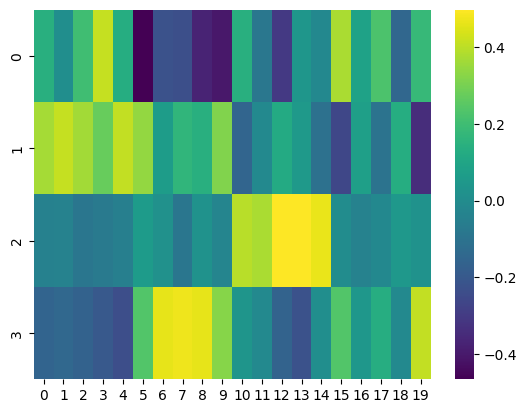

In [136]:
sns.heatmap(W, cmap="viridis")

# M

<Axes: >

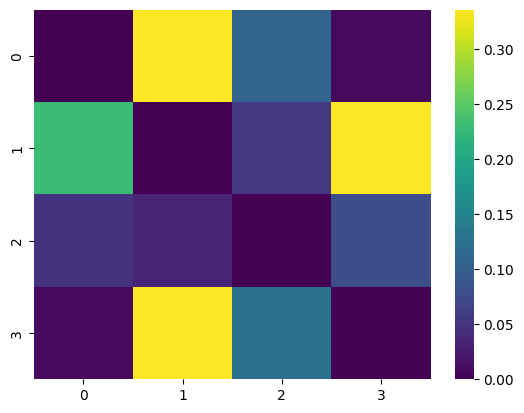

In [137]:
sns.heatmap(M, cmap="viridis")

In [162]:
X.shape

(5000, 20)

In [203]:
X_mean = np.vstack([a.mean(axis=1) for a in np.split(X, n_components, axis=1)])
X_mean.shape

(4, 5000)

In [204]:
x_cov = (X_mean @ X_mean.T) / X_mean.shape[0]
y_cov = Y.T @ Y / Y.shape[0]

In [205]:
x_cov.shape

(4, 4)

In [206]:
y_cov.shape

(4, 4)

<Axes: >

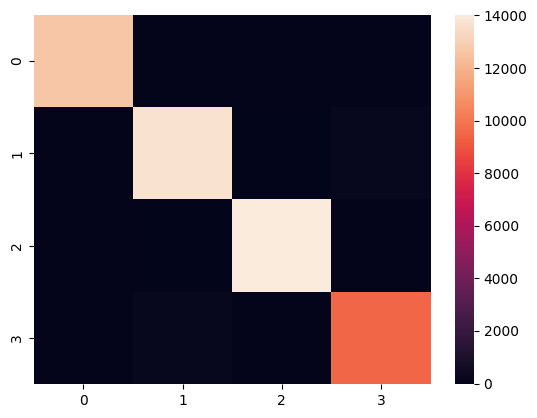

In [207]:
sns.heatmap(x_cov)

<Axes: >

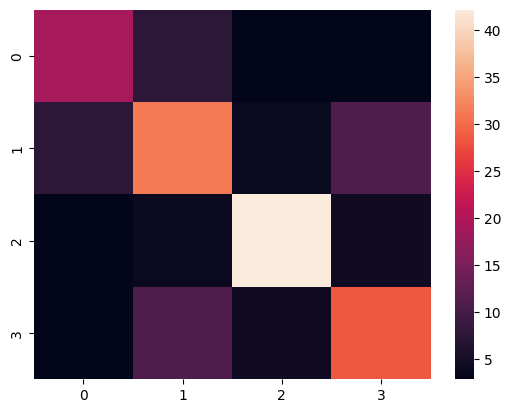

In [208]:
sns.heatmap(y_cov)

In [209]:
np.linalg.norm(x_cov - y_cov, ord="fro")

np.float64(25113.643125209706)

<Axes: >

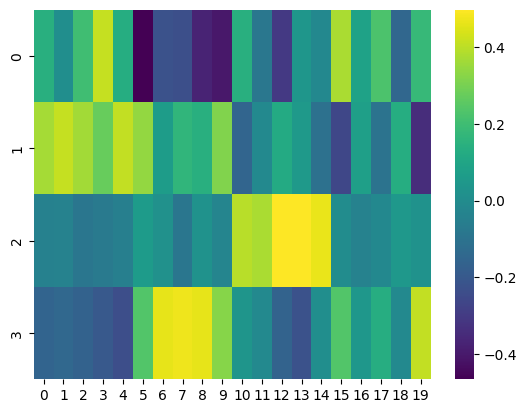

In [210]:
W_sorted = W[np.argsort(np.argmax(W, axis=1))]
sns.heatmap(W, cmap="viridis")